# Worked example: from the pickles to a science plot

A self-contained tour of what the pipeline produces, meant to be run **after**
`00_run_the_pipeline_illustrisTNG.py` has finished at least one simulation.
TNG50-4 is the cheapest one to generate, so it is the default here, but the
notebook picks up whatever `data_TNG50-*_snap*_*runs/` folders exist — set
`SIM_NAME` below to switch between TNG50-1/2/3/4.

What it covers:

1. **Load** the realizations and look at how the data is laid out
2. **Covering fraction** versus impact parameter — the headline measurement
3. **Concentration** from the post-processing helpers, validated against the
   known `c200`–`M200` relation
4. **Covering fraction at fixed mass, split by concentration** — a question the
   stored columns can answer that the covering fraction alone cannot

Nothing here needs the modified `fake_spectra`: the pickles are plain pandas and
`radii_skewers` imports its extraction dependencies lazily.

## 1. Setup

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- which simulation to look at ---------------------------------------
SIM_NAME = "TNG50-2"      # TNG50-1 / TNG50-2 / TNG50-3 / TNG50-4
SNAP_NUM = 25             # 25 -> z ~ 3 in TNG50

# Project root = the directory that contains tools/
PROJ_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "tools").is_dir())
sys.path.insert(0, str(PROJ_ROOT / "tools"))
import radii_skewers as rs

# The driver names its output folder data_<SIM>_snap<NNN>_<N>runs
candidates = sorted(PROJ_ROOT.glob(f"data_{SIM_NAME}_snap{SNAP_NUM:03d}_*runs"))
if not candidates:
    raise FileNotFoundError(
        f"No data folder for {SIM_NAME} snap {SNAP_NUM} under {PROJ_ROOT}.\n"
        f"Run instructions/00_run_the_pipeline_illustrisTNG.py first, or pick "
        f"one of: {[p.name for p in PROJ_ROOT.glob('data_*runs')]}")
DATA_DIR = candidates[0]

print("project root :", PROJ_ROOT)
print("data folder  :", DATA_DIR.name)
for f in sorted(DATA_DIR.glob("*.pkl")):
    print(f"   {f.name}  ({f.stat().st_size/1e6:.0f} MB)")

project root : /home/vroberto/FakeSpectra_DLAs
data folder  : data_TNG50-2_snap025_5runs
   TNG50-2_z3_637Halos_HCDMode_Stratified_run0_seed42.pkl  (1143 MB)
   TNG50-2_z3_637Halos_HCDMode_Stratified_run1_seed137.pkl  (1143 MB)
   TNG50-2_z3_637Halos_HCDMode_Stratified_run2_seed2025.pkl  (1143 MB)
   TNG50-2_z3_637Halos_HCDMode_Stratified_run3_seed999.pkl  (1143 MB)
   TNG50-2_z3_637Halos_HCDMode_Stratified_run4_seed31415.pkl  (1143 MB)


## 2. Loading

One pickle per realization. The DataFrame is one row per sightline; the shared
spectral grids and the snapshot constants live in `df.attrs`, so a single file
is enough to know what its own numbers mean.

In [2]:
def load_run(path):
    """One realization -> (DataFrame, metadata dict)."""
    df = pd.read_pickle(path)
    meta = dict(df.attrs)
    if "v_grid" not in meta:
        raise KeyError(f"{path}: no 'v_grid' in df.attrs -- not written by the "
                       "current pipeline.")
    return df, meta


def load_runs(data_dir):
    """Every realization in a folder -> (list of DataFrames, metadata)."""
    files = sorted(Path(data_dir).glob("*.pkl"))
    if not files:
        raise FileNotFoundError(f"no .pkl in {data_dir}")
    dfs, meta0 = [], None
    for f in files:
        df, meta = load_run(f)
        if meta0 is None:
            meta0 = meta
        else:
            assert meta["nbins"] == meta0["nbins"], f"{f.name}: nbins differs"
            assert np.allclose(meta["v_grid"], meta0["v_grid"]), \
                f"{f.name}: velocity grid differs -- runs are not comparable"
        dfs.append(df)
        print(f"  run {meta.get('run_id')} (seed {meta.get('seed')}): "
              f"{len(df):>7,} rows, {df['halo_id'].nunique()} haloes")
    return dfs, meta0


dfs, meta = load_runs(DATA_DIR)
df = dfs[0]
n_runs = len(dfs)
print(f"\n{n_runs} realizations | {SIM_NAME} at z = {meta['redshift']:.3f}")

  run 0 (seed 42): 231,231 rows, 637 haloes
  run 1 (seed 137): 231,231 rows, 637 haloes
  run 2 (seed 2025): 231,231 rows, 637 haloes
  run 3 (seed 999): 231,231 rows, 637 haloes
  run 4 (seed 31415): 231,231 rows, 637 haloes

5 realizations | TNG50-2 at z = 3.008


## 3. How the data is laid out

Two kinds of column. **Scalars** describe the halo and the geometry of the
sightline. **Arrays** are the spectra themselves: one `float32` array of
`nbins` values per row, every one of them sampled on the same
`df.attrs['v_grid']`.

The velocity grid is stored once rather than per row on purpose — repeating it
231,231 times would add gigabytes of duplication to each file.

In [3]:
scalars = [c for c in df.columns if not isinstance(df[c].iloc[0], np.ndarray)]
arrays  = [c for c in df.columns if isinstance(df[c].iloc[0], np.ndarray)]

print("SCALAR COLUMNS")
print(df[scalars].dtypes.to_string())
print("\nARRAY COLUMNS  (one array of nbins values per row)")
for c in arrays:
    lens = df[c].map(len).unique()
    print(f"  {c:<10} dtype={df[c].iloc[0].dtype}  lengths={lens}")

print(f"\nSHARED METADATA (df.attrs)")
for k in sorted(meta):
    val = meta[k]
    if isinstance(val, np.ndarray):
        print(f"  {k:<16} ndarray{val.shape}  [{val.min():.4g} .. {val.max():.4g}]")
    else:
        print(f"  {k:<16} {val!r}")

# Geometry: 3 sightlines at b = 0, 12 at every other impact parameter
radii = np.sort(df["r_multiplier"].unique())
print(f"\n{len(radii)} impact parameters, b = 0 to {radii.max():.1f} R_200")
print("sightlines per halo:", len(df) // df["halo_id"].nunique())
print(f"HCD sightlines: {df['is_hcd'].sum():,} / {len(df):,} "
      f"({100*df['is_hcd'].mean():.1f} %)")

SCALAR COLUMNS
halo_id             int64
halo_mass         float64
halo_r200         float64
halo_vmax         float64
redshift          float64
skewer_id           int64
axis                int64
position_tag       object
r_multiplier      float64
impact_kpc        float64
log_n_hi          float64
is_hcd               bool
vel_peak_shift    float64

ARRAY COLUMNS  (one array of nbins values per row)
  flux       dtype=float32  lengths=[396]
  n_hi_col   dtype=float32  lengths=[396]
  temp       dtype=float32  lengths=[396]

SHARED METADATA (df.attrs)
  box_size         35000.0
  chi_grid         ndarray(396,)  [-1.75e+04 .. 1.75e+04]
  dvbin            10.003903904835067
  hcd_log_nhi_cut  17.2
  lam_rest         1215.67
  length_unit_kpc  1.0
  modes            ('HCD_only',)
  nbins            396
  pixel_length_cm  1.0044685543543879e+23
  redshift         3.008131071630377
  run_id           0
  seed             42
  sim_name         'TNG50-2'
  snap_num         25
  v_grid       

A few invariants worth checking before trusting anything downstream. `is_hcd`
must be exactly `log_n_hi >= 17.2`, and a sightline that failed the cut must be
flat at F = 1 — that is a **selection outcome**, not missing data.

is_hcd == (log_n_hi >= 17.2)      : True
log_n_hi == 0 where not is_hcd     : True
non-HCD sightlines flat at F = 1   : True
flux within [0, 1]                 : [0.0000, 1.0000]


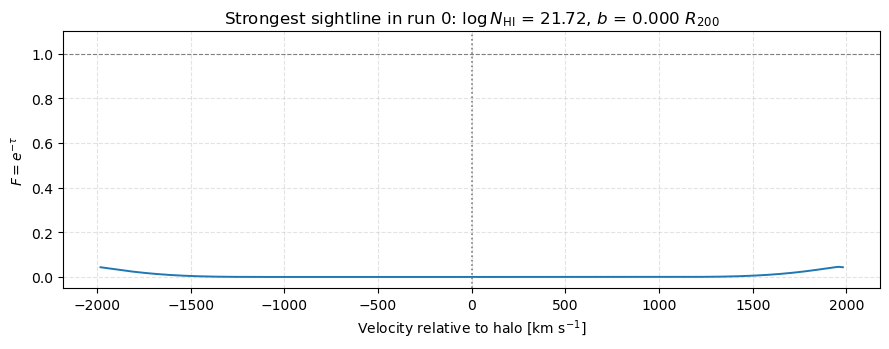

In [4]:
cut = meta["hcd_log_nhi_cut"]
hi, hc = df["log_n_hi"].to_numpy(), df["is_hcd"].to_numpy()

print(f"is_hcd == (log_n_hi >= {cut})      :", bool(np.all(hc == (hi >= cut))))
print("log_n_hi == 0 where not is_hcd     :", bool(np.all(hi[~hc] == 0.0)))
flat = all(np.allclose(np.asarray(f), 1.0) for f in df.loc[~hc, "flux"].head(200))
print("non-HCD sightlines flat at F = 1   :", flat)
fl = np.concatenate([np.asarray(f) for f in df["flux"].head(1000)])
print(f"flux within [0, 1]                 : [{fl.min():.4f}, {fl.max():.4f}]")

# one HCD spectrum, to see what a row actually holds
row = df[df["is_hcd"]].sort_values("log_n_hi").iloc[-1]
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(meta["v_grid"], np.asarray(row["flux"], float), color="tab:blue", lw=1.4)
ax.axhline(1.0, color="gray", ls="--", lw=0.8)
ax.axvline(0.0, color="gray", ls=":", lw=1.2)
ax.set_xlabel(r"Velocity relative to halo [km s$^{-1}$]")
ax.set_ylabel(r"$F = e^{-\tau}$")
ax.set_title(rf"Strongest sightline in run 0: $\log N_{{\rm HI}}$ = "
             rf"{row['log_n_hi']:.2f}, $b$ = {row['r_multiplier']:.3f} $R_{{200}}$")
ax.set_ylim(-0.05, 1.1)
ax.grid(True, ls="--", alpha=0.35)
plt.tight_layout(); plt.show()

## 4. Covering fraction versus impact parameter

The fraction of sightlines in each absorber class as a function of `b`. The
spread between realizations is sampling variance — the reason for running
several seeds in the first place.

The class boundaries come from `radii_skewers.CATEGORY_EDGES`, so this and the
`categorize()` helper can never drift apart.

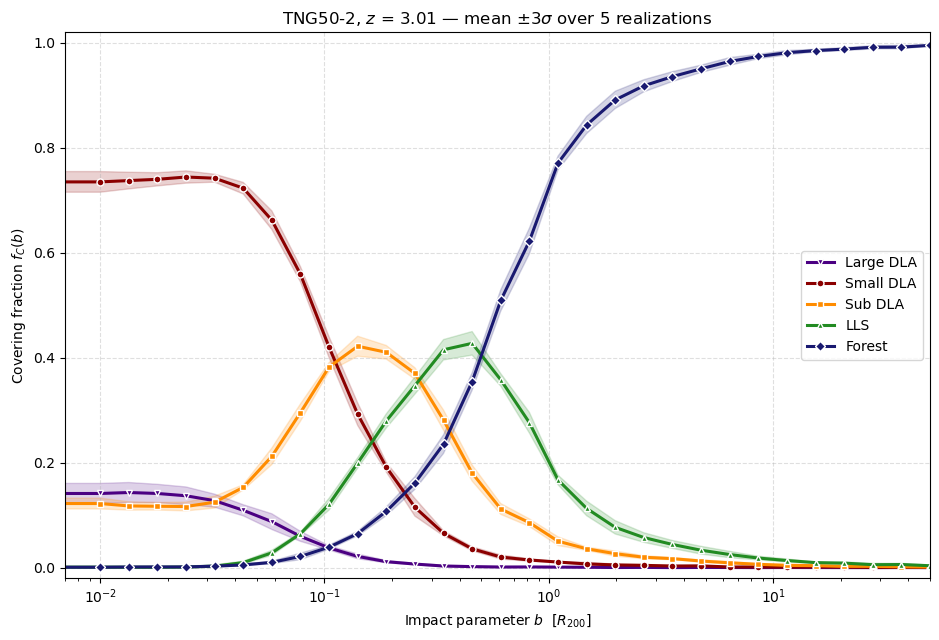

In [5]:
STYLE = {"Large_DLA": ("indigo", "v"), "Small_DLA": ("darkred", "o"),
         "Sub_DLA": ("darkorange", "s"), "LLS": ("forestgreen", "^"),
         "Forest": ("midnightblue", "D")}
EDGES = dict(zip(rs.CATEGORY_LABELS,
                 zip(rs.CATEGORY_EDGES[:-1], rs.CATEGORY_EDGES[1:])))


def covering_fractions(frames, radii, mask=None):
    """(n_runs, n_radii) array of covering fractions, per absorber class.

    `mask` is an optional per-frame boolean Series to restrict the sample
    (a mass bin, a concentration tercile, ...). Empty cells give NaN so they
    drop out of nanmean/nanstd instead of being counted as zero.
    """
    out = {c: np.full((len(frames), len(radii)), np.nan) for c in rs.CATEGORY_LABELS}
    counts = np.zeros((len(frames), len(radii)), dtype=int)
    for i, d in enumerate(frames):
        if mask is not None:
            d = d[mask[i]]
        groups = {k: v for k, v in d.groupby("r_multiplier")}
        for j, b in enumerate(radii):
            sub = groups.get(b)
            if sub is None or len(sub) == 0:
                continue
            nhi = sub["log_n_hi"].to_numpy()
            counts[i, j] = len(sub)
            for cls, (lo, hi_) in EDGES.items():
                out[cls][i, j] = np.count_nonzero((nhi >= lo) & (nhi < hi_)) / len(sub)
    return out, counts


frac, counts = covering_fractions(dfs, radii)

fig, ax = plt.subplots(figsize=(9.5, 6.5))
for cls, (colour, marker) in STYLE.items():
    m = np.nanmean(frac[cls], axis=0)
    # ddof=1: sample standard deviation. With 5 realizations ddof=0 would
    # understate the spread by about 11 per cent.
    s = np.nanstd(frac[cls], axis=0, ddof=1) if n_runs > 1 else np.zeros_like(m)
    ax.fill_between(radii, np.clip(m - 3*s, 0, None), np.clip(m + 3*s, None, 1),
                    color=colour, alpha=0.18)
    ax.plot(radii, m, color=colour, lw=2.2, marker=marker, ms=5, mec="white",
            label=cls.replace("_", " "))

ax.set_xscale("log")
ax.set_xlim(radii[radii > 0].min() * 0.7, radii.max())
ax.set_ylim(-0.02, 1.02)
ax.set_xlabel(r"Impact parameter $b$  [$R_{200}$]")
ax.set_ylabel(r"Covering fraction $f_C(b)$")
ax.set_title(rf"{SIM_NAME}, $z$ = {meta['redshift']:.2f} — mean $\pm 3\sigma$ "
             rf"over {n_runs} realizations")
ax.grid(True, ls="--", alpha=0.4)
ax.legend(loc="center right", fontsize=10)
plt.tight_layout(); plt.show()

## 5. Concentration, from the post-processing helpers

`halo_c200` is not stored in the file — it is derived on demand from
`halo_vmax` (the peak of the circular-velocity curve of the central subhalo,
read from the group catalogue) and `halo_v200` (computed from `halo_mass` and
`halo_r200`). For an NFW profile the ratio `Vmax/V200` is a monotonic function
of concentration alone, which is what `rs.add_concentration` inverts.

NaN is meaningful here: it marks haloes with no central subhalo, or with
`Vmax/V200 <= 1`, i.e. `c < 2.163`, below the range where the inversion exists.
Keep them out of the statistics rather than filling them.

In [6]:
HUBBLE_H = 0.6774
for d in dfs:
    rs.add_concentration(d)
    d["halo_mass_msun"] = d["halo_mass"] * 1e10 / HUBBLE_H

# One row per halo: concentration is a halo property, not a sightline property.
#
# NOTE: pd.concat on these frames fails outright. pandas compares the .attrs of
# the operands with `==`, and ours hold numpy arrays (v_grid, wave_grid,
# chi_grid), so the comparison raises
#     ValueError: The truth value of an array with more than one element ...
# Clearing .attrs on the small per-run tables before concatenating sidesteps it.
# The same applies any time you stack realizations -- keep meta separately.
halo_cols = ["halo_mass_msun", "halo_r200", "halo_vmax", "halo_v200", "halo_c200"]
tables = []
for i, d in enumerate(dfs):
    t = d.groupby("halo_id")[halo_cols].first().reset_index()
    t["run"] = i
    t.attrs = {}
    tables.append(t)
haloes = pd.concat(tables, ignore_index=True)

good = haloes["halo_c200"].notna()
print(f"{good.sum()} / {len(haloes)} haloes with a defined c200 "
      f"({100*(~good).mean():.1f} % NaN)")
print(haloes.loc[good, ["halo_mass_msun", "halo_v200", "halo_vmax", "halo_c200"]]
      .describe().T[["mean", "std", "min", "max"]])

1938 / 3185 haloes with a defined c200 (39.2 % NaN)
                        mean           std           min           max
halo_mass_msun  4.059795e+11  7.888382e+11  1.004139e+10  8.888161e+12
halo_v200       1.397283e+02  7.242994e+01  5.100762e+01  4.897414e+02
halo_vmax       1.653061e+02  1.302620e+02  5.118288e+01  1.173214e+03
halo_c200       8.211161e+00  1.793022e+01  2.196211e+00  2.375105e+02


### Validation: the `c200`–`M200` relation

Concentration should fall slowly with halo mass, roughly as a power law with a
shallow negative slope, with a scatter of about 0.1 dex in log c at fixed mass.
If the fitted slope came out positive, or the normalisation were wildly off, it
would mean `halo_vmax` or the units in `halo_v200` are wrong — this plot is the
cheapest way to catch that.

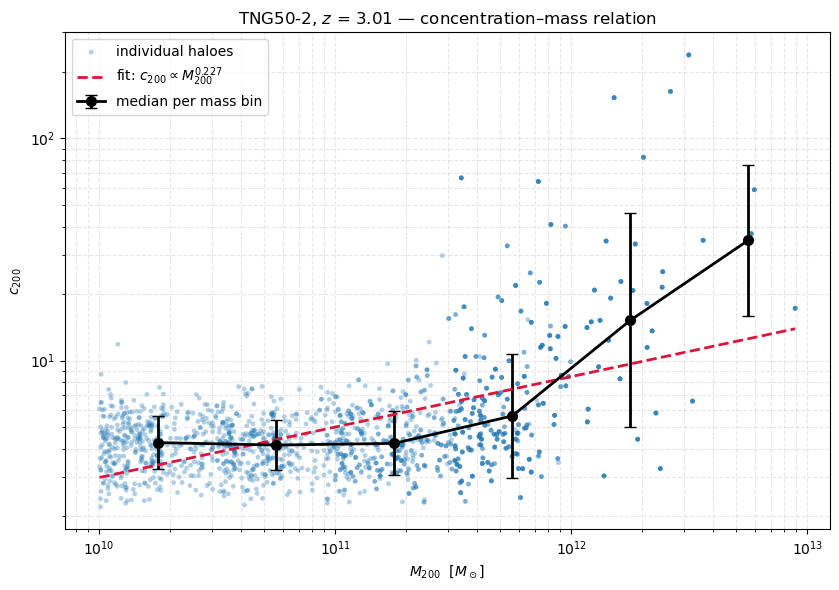

fitted slope   : +0.227   (expect a shallow negative value at z~3)
scatter in log c: 0.246 dex


In [7]:
h = haloes[good]
logM, logc = np.log10(h["halo_mass_msun"]), np.log10(h["halo_c200"])
slope, intercept = np.polyfit(logM, logc, 1)

# median in mass bins, to see the trend through the scatter
bins = np.arange(np.floor(logM.min()*2)/2, np.ceil(logM.max()*2)/2 + 0.01, 0.5)
idx = np.digitize(logM, bins)
bx, by, be = [], [], []
for i in range(1, len(bins)):
    m = idx == i
    if m.sum() >= 5:
        bx.append(0.5*(bins[i-1] + bins[i]))
        by.append(np.median(logc[m]))
        be.append(np.std(logc[m], ddof=1))

fig, ax = plt.subplots(figsize=(8.5, 6))
ax.scatter(10**logM, 10**logc, s=12, alpha=0.35, color="tab:blue",
           edgecolor="none", label="individual haloes")
if bx:
    ax.errorbar(10**np.array(bx), 10**np.array(by),
                yerr=[10**np.array(by) - 10**(np.array(by) - np.array(be)),
                      10**(np.array(by) + np.array(be)) - 10**np.array(by)],
                fmt="o-", color="black", lw=2, ms=7, capsize=4,
                label="median per mass bin")
xx = np.linspace(logM.min(), logM.max(), 50)
ax.plot(10**xx, 10**(intercept + slope*xx), ls="--", color="crimson", lw=2,
        label=rf"fit: $c_{{200}} \propto M_{{200}}^{{{slope:.3f}}}$")

ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel(r"$M_{200}$  [$M_\odot$]")
ax.set_ylabel(r"$c_{200}$")
ax.set_title(rf"{SIM_NAME}, $z$ = {meta['redshift']:.2f} — concentration–mass relation")
ax.grid(True, which="both", ls="--", alpha=0.3)
ax.legend(fontsize=10)
plt.tight_layout(); plt.show()

print(f"fitted slope   : {slope:+.3f}   (expect a shallow negative value at z~3)")
print(f"scatter in log c: {np.std(logc - (intercept + slope*logM), ddof=1):.3f} dex")

## 6. Does concentration change the HI covering fraction at fixed mass?

Here is something the stored columns can answer but the covering fraction alone
cannot. At fixed halo mass, a more concentrated halo assembled earlier and has a
denser inner region. Does that translate into more HCD absorption along
sightlines that pass close to the centre?

The comparison has to be **at fixed mass**, because concentration correlates
with mass and mass drives the covering fraction. So: pick one mass bin, split
its haloes at the median concentration, and compare the two halves. Any
difference that survives is concentration, not mass.

mass bin 10^11.0-10^12.0 M_sun: 1010 haloes, median c200 = 4.71
sightlines: 183,315 low-c, 183,315 high-c


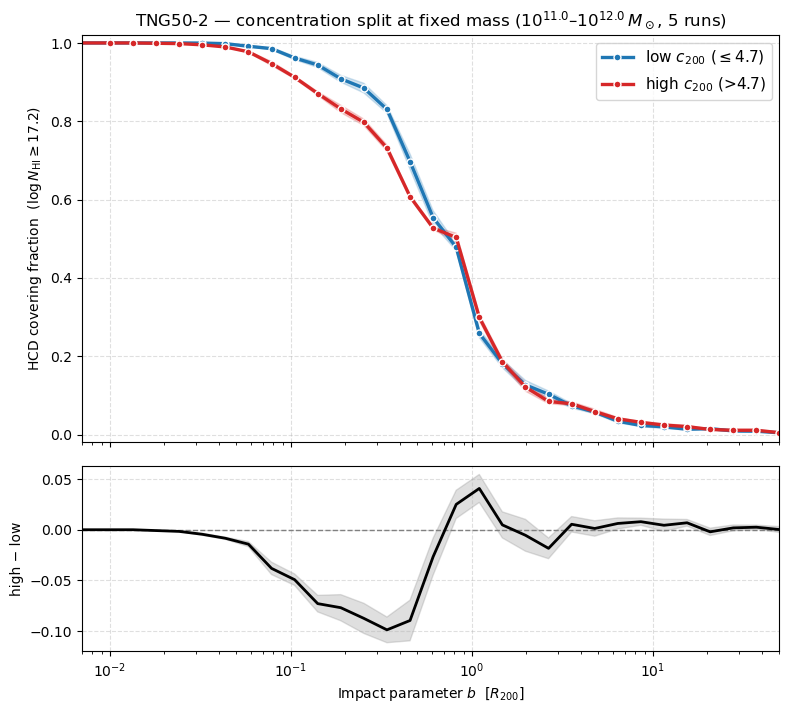


Mean HCD covering fraction inside R_200:
  low  c200: 0.896
  high c200: 0.864
  difference: -0.032 +- 0.007 (1 sigma across realizations)


In [8]:
MASS_LO, MASS_HI = 11.0, 12.0     # log10 M_sun; widen if the sample is thin

# Halo-level split, then map the labels back onto the sightlines
sel = haloes[good & haloes["halo_mass_msun"].between(10**MASS_LO, 10**MASS_HI)]
c_median = sel["halo_c200"].median()
print(f"mass bin 10^{MASS_LO}-10^{MASS_HI} M_sun: {len(sel)} haloes, "
      f"median c200 = {c_median:.2f}")

low_mask, high_mask = [], []
for i, d in enumerate(dfs):
    ids = sel[sel["run"] == i].set_index("halo_id")["halo_c200"]
    c_of_row = d["halo_id"].map(ids)
    low_mask.append(c_of_row.notna() & (c_of_row <= c_median))
    high_mask.append(c_of_row.notna() & (c_of_row > c_median))
print(f"sightlines: {sum(m.sum() for m in low_mask):,} low-c, "
      f"{sum(m.sum() for m in high_mask):,} high-c")

frac_lo, n_lo = covering_fractions(dfs, radii, mask=low_mask)
frac_hi, n_hi = covering_fractions(dfs, radii, mask=high_mask)

# "HCD" = anything at or above the 17.2 cut, i.e. everything except Forest
def hcd_fraction(fr):
    return sum(fr[c] for c in rs.CATEGORY_LABELS if c != "Forest")

fig, (ax, axr) = plt.subplots(2, 1, figsize=(9, 8), sharex=True,
                              gridspec_kw={"height_ratios": [2.2, 1], "hspace": 0.08})

curves = {}
for label, fr, colour in [(rf"low $c_{{200}}$ ($\leq${c_median:.1f})", frac_lo, "tab:blue"),
                          (rf"high $c_{{200}}$ (>{c_median:.1f})", frac_hi, "tab:red")]:
    h = hcd_fraction(fr)
    m = np.nanmean(h, axis=0)
    s = np.nanstd(h, axis=0, ddof=1) if n_runs > 1 else np.zeros_like(m)
    curves[label] = (m, s)
    ax.fill_between(radii, np.clip(m - s, 0, None), np.clip(m + s, None, 1),
                    color=colour, alpha=0.20)
    ax.plot(radii, m, color=colour, lw=2.4, marker="o", ms=5, mec="white", label=label)

(m_lo, s_lo), (m_hi, s_hi) = curves.values()
with np.errstate(invalid="ignore", divide="ignore"):
    diff = m_hi - m_lo
    err = np.sqrt(s_hi**2 + s_lo**2)
axr.axhline(0, color="gray", ls="--", lw=1)
axr.fill_between(radii, diff - err, diff + err, color="gray", alpha=0.25)
axr.plot(radii, diff, color="black", lw=2)

ax.set_xscale("log")
ax.set_xlim(radii[radii > 0].min() * 0.7, radii.max())
ax.set_ylim(-0.02, 1.02)
ax.set_ylabel(r"HCD covering fraction  ($\log N_{\rm HI} \geq 17.2$)")
ax.set_title(rf"{SIM_NAME} — concentration split at fixed mass "
             rf"($10^{{{MASS_LO}}}$–$10^{{{MASS_HI}}}\,M_\odot$, {n_runs} runs)")
ax.grid(True, ls="--", alpha=0.4)
ax.legend(fontsize=11)

axr.set_xlabel(r"Impact parameter $b$  [$R_{200}$]")
axr.set_ylabel("high − low")
axr.grid(True, ls="--", alpha=0.4)
plt.show()

inner = radii <= 1.0
print(f"\nMean HCD covering fraction inside R_200:")
print(f"  low  c200: {np.nanmean(m_lo[inner]):.3f}")
print(f"  high c200: {np.nanmean(m_hi[inner]):.3f}")
print(f"  difference: {np.nanmean(m_hi[inner] - m_lo[inner]):+.3f} "
      f"+- {np.nanmean(err[inner]):.3f} (1 sigma across realizations)")

**How to read the bottom panel.** It is the difference between the two curves,
with the realization-to-realization scatter added in quadrature. If it sits on
zero within the band, concentration does not measurably change the HI covering
fraction at this mass — which is itself a result. If it is positive at small `b`
and consistent with zero further out, concentration is reshaping the inner HI
distribution without changing the total extent.

Two caveats before reading too much into it. A median split at fixed mass is
blunt: with few haloes per bin the two halves also differ slightly in mass, so
check that `sel.groupby(sel.halo_c200 > c_median).halo_mass_msun.median()` gives
nearly the same value on both sides. And the mass bin has to be narrow enough
that mass is genuinely controlled, but wide enough to keep the samples usable —
widen `MASS_LO`/`MASS_HI` if the error band swallows the signal.

## 7. Where to go next

`rs.add_moments(df)` adds the spectral shape — equivalent width, velocity
dispersion, skewness, kurtosis and the N_HI-weighted temperature `T_hi` — all
recomputed from `flux`, `n_hi_col` and `temp`. Two natural continuations:

* **Empirical curve of growth.** Plot `eq_width` against `log_n_hi` for the HCD
  sightlines. The saturated plateau and the square-root damped branch should
  both appear; the vertical scatter at fixed N_HI is the spread of effective
  Doppler parameters.
* **Temperature of the absorbing gas.** `temp` is the N_HI-weighted temperature
  per pixel, non-zero only where the HCD structure has gas, so
  `temp[temp > 0]` is already the temperature of the HCD gas itself.

One gotcha: `kurtosis` collides with the pandas `Series.kurtosis()` method. Use
`row["kurtosis"]`, never `row.kurtosis`.

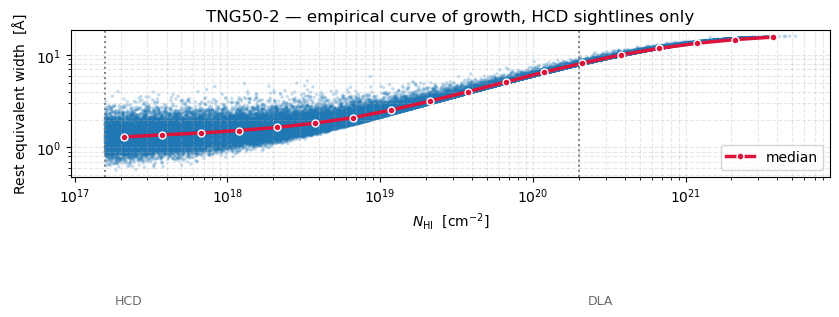

In [9]:
rs.add_moments(df)
hcd = df[df["is_hcd"] & (df["eq_width"] > 0)]

fig, ax = plt.subplots(figsize=(8.5, 6))
ax.scatter(10**hcd["log_n_hi"], hcd["eq_width"], s=6, alpha=0.25,
           color="tab:blue", edgecolor="none")

bins = np.arange(17.2, hcd["log_n_hi"].max() + 0.25, 0.25)
idx = np.digitize(hcd["log_n_hi"], bins)
bx, by = [], []
for i in range(1, len(bins)):
    m = idx == i
    if m.sum() >= 5:
        bx.append(0.5*(bins[i-1] + bins[i]))
        by.append(np.median(hcd["eq_width"][m]))
ax.plot(10**np.array(bx), by, color="crimson", lw=2.5, marker="o", ms=5,
        mec="white", label="median")

for x, lab in [(10**17.2, "HCD"), (10**20.3, "DLA")]:
    ax.axvline(x, color="gray", ls=":", lw=1.4)
    ax.text(x*1.15, ax.get_ylim()[0]*1.5 if ax.get_ylim()[0] > 0 else 0.02,
            lab, fontsize=9, color="dimgray")

ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel(r"$N_{\rm HI}$  [cm$^{-2}$]")
ax.set_ylabel(r"Rest equivalent width  [$\rm\AA$]")
ax.set_title(rf"{SIM_NAME} — empirical curve of growth, HCD sightlines only")
ax.grid(True, which="both", ls="--", alpha=0.3)
ax.legend(fontsize=10)
plt.tight_layout(); plt.show()